# 2R2C with internal mass — heat balance and state-space matrices

```
                 Phi_HC
                   |
   T_a ---R_ia--- T_i ---R_im--- T_m
                   |              |
                  C_i            C_m
```

| symbol | unit | meaning |
|---|---|---|
| $T_i$ | °C | indoor air (state, measured) |
| $T_m$ | °C | internal mass: stored products, shelves (state, hidden) |
| $T_a$ | °C | surrounding room (disturbance) |
| $\Phi_{HC}$ | W | cooling (<0) power (control), $\Phi_{HC} = -P_{el}$ |
| $R_{ia}$ | K/W | air ↔ surrounding room |
| $R_{im}$ | K/W | air ↔ internal mass (convection to the products) |
| $C_i$, $C_m$ | J/K | capacities of the air and of the internal mass |
| $\alpha_m$ | – | share of $\Phi_{HC}$ acting directly on the mass (default 0: forced-air evaporator) |

The internal mass exchanges heat only with the air; it has no direct path to $T_a$.

In [1]:
import numpy as np
import sympy as sp
from IPython.display import display, Math

sp.init_printing()

def show(lhs, expr):
    display(Math(lhs + " = " + sp.latex(expr)))

## Heat balances

$$C_i \frac{dT_i}{dt} = \frac{T_a - T_i}{R_{ia}} + \frac{T_m - T_i}{R_{im}} + (1-\alpha_m)\,\Phi_{HC}$$

$$C_m \frac{dT_m}{dt} = \frac{T_i - T_m}{R_{im}} + \alpha_m\,\Phi_{HC}$$

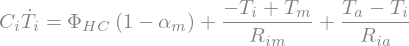

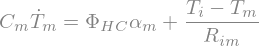

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [2]:
T_i, T_m, T_a, Phi_HC = sp.symbols("T_i T_m T_a Phi_HC", real=True)
R_ia, R_im, C_i, C_m = sp.symbols("R_ia R_im C_i C_m", positive=True)
alpha_m = sp.Symbol("alpha_m", nonnegative=True)
dT_i, dT_m = sp.symbols(r"\dot{T}_i \dot{T}_m")

balances = [
    sp.Eq(C_i * dT_i, (T_a - T_i) / R_ia + (T_m - T_i) / R_im + (1 - alpha_m) * Phi_HC),
    sp.Eq(C_m * dT_m, (T_i - T_m) / R_im + alpha_m * Phi_HC),
]
for b in balances:
    display(b)

sol = sp.solve(balances, [dT_i, dT_m], dict=True)[0]
f = sp.Matrix([sp.expand(sol[dT_i]), sp.expand(sol[dT_m])])
show(r"\dot{T}_i", f[0])
show(r"\dot{T}_m", f[1])

## State-space form

The balances are linear in the states $x$, the control $u$ and the disturbances $d$, so

$$\dot x = A x + B u + E d, \qquad A = \frac{\partial f}{\partial x},\; B = \frac{\partial f}{\partial u},\; E = \frac{\partial f}{\partial d}.$$

The Jacobians are taken symbolically below, and the cell after that checks that $A x + B u + E d$ reproduces $f$ exactly.

In [3]:
x = sp.Matrix([T_i, T_m])
u = sp.Matrix([Phi_HC])
d = sp.Matrix([T_a])
A = f.jacobian(x)
B = f.jacobian(u)
E = f.jacobian(d)

show(r"x", x); show(r"u", u); show(r"d", d)
show(r"A", A)
show(r"B", B)
show(r"E", E)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
assert sp.simplify(A * x + B * u + E * d - f) == sp.zeros(*f.shape)
print("A x + B u + E d == f  ✓")

A x + B u + E d == f  ✓


## Time constants, steady state and limits

The two time constants are $\tau_{1,2} = -1/\lambda_{1,2}(A)$. In steady state no heat flows into the mass, so (for $\alpha_m = 0$) $T_{m,ss} = T_{i,ss} = T_a + R_{ia}\Phi_{HC}$. The limits $R_{im} \to \infty$ (mass decoupled) and $R_{im} \to 0$ (mass lumped with the air) both reduce the model to 1R1C, with $C_i$ and $C_i + C_m$ respectively; this is what the identification shows when the data cannot separate the two modes.

In [5]:
lam = list(A.eigenvals().keys())
for k, l in enumerate(lam, 1):
    show(rf"\lambda_{k}", sp.simplify(l))

ss = sp.solve(list(f.subs(alpha_m, 0)), [T_i, T_m], dict=True)[0]
show(r"T_{i,ss}", ss[T_i]); show(r"T_{m,ss}", ss[T_m])

# product and sum of the eigenvalues (det and trace of A)
show(r"\lambda_1 \lambda_2 = \det A", sp.simplify(A.det()))
show(r"\lambda_1 + \lambda_2 = \operatorname{tr} A", sp.simplify(A.trace()))

# R_im -> oo: the T_i row becomes the 1R1C balance with C_i
show(r"\lim_{R_{im}\to\infty} \dot{T}_i", sp.limit(f[0].subs(alpha_m, 0), R_im, sp.oo))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Discretization (as implemented in the toolbox)

With the inputs held constant over each step (zero-order hold), the exact one-step map is

$$x_k = A_d x_{k-1} + B_d \begin{bmatrix} u_k \\ d_k \end{bmatrix}, \qquad A_d = e^{A\,\Delta t}, \qquad B_d = \int_0^{\Delta t} e^{A s}\,ds\,[B \;\; E],$$

which `rctoolbox.models.discretization.zoh_discretize` evaluates with the augmented-matrix exponential

$$\exp\!\left(\begin{bmatrix} A & [B\;E] \\ 0 & 0 \end{bmatrix}\Delta t\right) = \begin{bmatrix} A_d & B_d \\ 0 & I \end{bmatrix}.$$

The input column order is therefore the stacked vector $[u; d]$ used by `calc_temperature`. The forward-Euler option steps $x_k = x_{k-1} + \Delta t\,(A x_{k-1} + B u_k + E d_k)$, which is stable only for $\Delta t < 2\tau_{\min}$.

## Check against the toolbox implementation

The symbolic matrices are evaluated for random parameter values and compared with `calc_matrices()` of the model class.

In [6]:
from rctoolbox.models.rc.two_r2c_im.model import TwoR2CInternalMass

rng = np.random.default_rng(0)
for _ in range(5):
    p = {"R_ia": rng.uniform(1e-3, 1), "R_im": rng.uniform(1e-4, 1),
         "C_i": rng.uniform(1e3, 1e7), "C_m": rng.uniform(1e4, 1e8), "alpha_m": rng.uniform(0, 1)}
    model = TwoR2CInternalMass()
    model.set_params(p)
    A_num, B_num, E_num = model.calc_matrices()

    subs = {R_ia: p["R_ia"], R_im: p["R_im"], C_i: p["C_i"], C_m: p["C_m"], alpha_m: p["alpha_m"]}
    for name, S, N in [("A", A, A_num), ("B", B, B_num), ("E", E, E_num)]:
        S_num = np.array(S.subs(subs), dtype=float)
        assert np.allclose(S_num, N, rtol=1e-12, atol=0), name
print("symbolic A, B, E == TwoR2CInternalMass.calc_matrices()  ✓")

symbolic A, B, E == TwoR2CInternalMass.calc_matrices()  ✓
